In [8]:
# 10_attention_fusion.ipynb

#  CELL 1: Setup  
from __future__ import annotations

import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from sklearn.metrics import (
    accuracy_score, classification_report, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

OUTPUT_DIR = Path("./data/processed")
MODEL_DIR = Path("./models")
RESULT_DIR = Path("./results")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

torch.manual_seed(42)
np.random.seed(42)
IMG_SIZE = 224


Device: cuda


In [9]:
#  CELL 2: Transforms  
train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


In [10]:
# ==================== CELL 3: Inlined Dataset Class ====================
EXCLUDE_COLS = {"ID", "has_cad", "max_stenosis", "num_diseased_vessels"}

def feature_columns(clinical_df):
    return [c for c in clinical_df.columns if c not in EXCLUDE_COLS]


class AngioCADDataset(Dataset):
    def __init__(self, patient_df, frames_df, clinical_df, transform=None,
                 aggregate="mean"):
        self.patients = patient_df.reset_index(drop=True)
        self.frames = frames_df
        self.clinical = clinical_df.set_index("ID")
        self.transform = transform
        self.aggregate = aggregate
        self.feature_cols = feature_columns(clinical_df)

    def __len__(self):
        return len(self.patients)

    def _load_frames(self, pid):
        subset = self.frames[self.frames["ID"] == str(int(pid))]
        tensors = []
        for path in subset["path"].tolist():
            try:
                img = Image.open(path).convert("RGB")
                tensors.append(self.transform(img) if self.transform
                               else transforms.ToTensor()(img))
            except Exception:
                continue
        return tensors

    def _aggregate(self, tensors):
        if not tensors:
            return torch.zeros(3, IMG_SIZE, IMG_SIZE)
        stack = torch.stack(tensors)
        if self.aggregate == "max":
            return stack.max(dim=0).values
        return stack.mean(dim=0)

    def __getitem__(self, idx):
        row = self.patients.iloc[idx]
        pid = int(row["ID"])
        img = self._aggregate(self._load_frames(pid))
        clinical = self.clinical.loc[pid, self.feature_cols].values.astype(np.float32)
        label = torch.tensor(int(row["has_cad"]), dtype=torch.long)
        return img, torch.from_numpy(clinical), label

In [11]:
# ==================== CELL 4: Cross-Attention Model ====================
class CrossAttentionBlock(nn.Module):
    """Multi-head cross-attention with residual + FFN."""
    def __init__(self, d_model=256, n_heads=8, dropout=0.1):
        super().__init__()
        self.attn = nn.MultiheadAttention(
            embed_dim=d_model, num_heads=n_heads,
            dropout=dropout, batch_first=True,
        )
        self.norm_q = nn.LayerNorm(d_model)
        self.norm_kv = nn.LayerNorm(d_model)
        self.norm_out = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_model * 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model * 2, d_model),
        )

    def forward(self, query, key_value):
        q = self.norm_q(query)
        kv = self.norm_kv(key_value)
        attn_out, weights = self.attn(q, kv, kv, need_weights=True)
        x = query + attn_out
        x = x + self.ffn(self.norm_out(x))
        return x, weights


class ImageTokenEncoder(nn.Module):
    """ResNet-18 → projected to N tokens."""
    def __init__(self, out_dim=256, n_tokens=4, pretrained=True):
        super().__init__()
        weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        backbone = models.resnet18(weights=weights)
        feat_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.backbone = backbone
        self.proj = nn.Linear(feat_dim, n_tokens * out_dim)
        self.n_tokens = n_tokens
        self.out_dim = out_dim

    def forward(self, x):
        features = self.backbone(x)
        tokens = self.proj(features)
        return tokens.view(-1, self.n_tokens, self.out_dim)


class ClinicalTokenEncoder(nn.Module):
    """Each clinical feature becomes its own token, plus a [CLS] token."""
    def __init__(self, in_dim, out_dim=256):
        super().__init__()
        self.per_feature_proj = nn.Sequential(
            nn.Linear(1, 64), nn.GELU(),
            nn.Linear(64, out_dim),
        )
        self.feature_embedding = nn.Parameter(torch.randn(1, in_dim, out_dim) * 0.02)
        self.cls_token = nn.Parameter(torch.randn(1, 1, out_dim) * 0.02)
        self.norm = nn.LayerNorm(out_dim)
        self.in_dim = in_dim

    def forward(self, x):
        x_expanded = x.unsqueeze(-1)
        tokens = self.per_feature_proj(x_expanded)
        tokens = tokens + self.feature_embedding
        cls = self.cls_token.expand(x.size(0), -1, -1)
        tokens = torch.cat([cls, tokens], dim=1)
        return self.norm(tokens)


class CrossAttentionFusionModel(nn.Module):
    """Main model: bidirectional cross-attention between modalities."""
    def __init__(self, clinical_dim, num_classes=2,
                 d_model=256, n_heads=8, n_cross_layers=2):
        super().__init__()
        self.img_enc = ImageTokenEncoder(out_dim=d_model, n_tokens=4)
        self.clin_enc = ClinicalTokenEncoder(in_dim=clinical_dim, out_dim=d_model)
        self.d_model = d_model

        self.img_to_clin = nn.ModuleList([
            CrossAttentionBlock(d_model, n_heads) for _ in range(n_cross_layers)
        ])
        self.clin_to_img = nn.ModuleList([
            CrossAttentionBlock(d_model, n_heads) for _ in range(n_cross_layers)
        ])

        self.img_pool = nn.Sequential(nn.Linear(d_model, d_model), nn.Tanh())
        self.clin_pool = nn.Sequential(nn.Linear(d_model, d_model), nn.Tanh())
        self.classifier = nn.Sequential(
            nn.LayerNorm(d_model * 2),
            nn.Linear(d_model * 2, 128), nn.GELU(), nn.Dropout(0.4),
            nn.Linear(128, num_classes),
        )

    def forward(self, image, clinical, return_attention=False):
        img_tokens = self.img_enc(image)
        clin_tokens = self.clin_enc(clinical)

        attn_maps = {"img_to_clin": [], "clin_to_img": []}

        for i2c, c2i in zip(self.img_to_clin, self.clin_to_img):
            img_tokens, w_i2c = i2c(img_tokens, clin_tokens)
            clin_tokens, w_c2i = c2i(clin_tokens, img_tokens)
            if return_attention:
                attn_maps["img_to_clin"].append(w_i2c.detach().cpu())
                attn_maps["clin_to_img"].append(w_c2i.detach().cpu())

        img_vec = img_tokens.mean(dim=1)
        clin_vec = clin_tokens[:, 0, :]  # CLS token

        img_vec = self.img_pool(img_vec)
        clin_vec = self.clin_pool(clin_vec)
        fused = torch.cat([img_vec, clin_vec], dim=1)

        logits = self.classifier(fused)
        if return_attention:
            return logits, attn_maps
        return logits

In [12]:
# ==================== CELL 5: Focal Loss ====================
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0, weight=None):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma
        if weight is not None:
            self.register_buffer("weight", weight)
        else:
            self.weight = None
    def forward(self, logits, targets):
        ce = nn.functional.cross_entropy(logits, targets,
                                         weight=self.weight, reduction="none")
        pt = torch.exp(-ce)
        return (self.alpha * (1.0 - pt) ** self.gamma * ce).mean()


In [13]:
# ==================== CELL 6: Load Data ====================
clinical_df = pd.read_csv(OUTPUT_DIR / "clinical_features_merged.csv")
frames_df = pd.read_csv(OUTPUT_DIR / "frames_index.csv")
frames_df["ID"] = frames_df["ID"].astype(str)

with open(OUTPUT_DIR / "splits.json") as f:
    splits = json.load(f)
with open(OUTPUT_DIR / "class_weights.json") as f:
    class_weights = json.load(f)

train_df = clinical_df[clinical_df["ID"].isin(splits["train"])]
val_df = clinical_df[clinical_df["ID"].isin(splits["val"])]
test_df = clinical_df[clinical_df["ID"].isin(splits["test"])]

BATCH_SIZE = 16
train_ds = AngioCADDataset(train_df, frames_df, clinical_df, transform=train_tfms)
val_ds = AngioCADDataset(val_df, frames_df, clinical_df, transform=eval_tfms)
test_ds = AngioCADDataset(test_df, frames_df, clinical_df, transform=eval_tfms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f"Train {len(train_ds)} | Val {len(val_ds)} | Test {len(test_ds)}")

clinical_dim = len(train_ds.feature_cols)



Train 255 | Val 46 | Test 76


In [14]:
# ==================== CELL 7: Train/Eval Helpers ====================
def train_epoch_attn(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    for image, clinical, y in loader:
        image = image.to(device, non_blocking=True)
        clinical = clinical.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(image, clinical)
        loss = criterion(logits, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        running_loss += loss.item() * image.size(0)
    return running_loss / len(loader.dataset)


def evaluate_attn(model, loader, device):
    model.eval()
    preds, probs, labels = [], [], []
    with torch.no_grad():
        for image, clinical, y in loader:
            image = image.to(device)
            clinical = clinical.to(device)
            logits = model(image, clinical)
            probs.append(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            preds.append(logits.argmax(dim=1).cpu().numpy())
            labels.append(y.numpy())
    y_true = np.concatenate(labels)
    y_pred = np.concatenate(preds)
    y_prob = np.concatenate(probs)
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "auc": float(roc_auc_score(y_true, y_prob)) if len(np.unique(y_true)) > 1 else 0.5,
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "y_true": y_true, "y_prob": y_prob,
    }



In [15]:
# ==================== CELL 8: Train ====================
EPOCHS = 50
LR = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 8

model = CrossAttentionFusionModel(
    clinical_dim=clinical_dim, d_model=256, n_heads=8, n_cross_layers=2,
).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}")

weight_tensor = torch.tensor([class_weights["0"], class_weights["1"]],
                             dtype=torch.float32).to(DEVICE)
criterion = FocalLoss(alpha=0.25, gamma=2.0, weight=weight_tensor)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

history = []
best_auc, best_epoch, no_improve = -1.0, -1, 0

print("=" * 72)
print("TRAINING CROSS-ATTENTION FUSION MODEL")
print("=" * 72)

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss = train_epoch_attn(model, train_loader, criterion, optimizer, DEVICE)
    scheduler.step()
    val_metrics = evaluate_attn(model, val_loader, DEVICE)
    dt = time.time() - t0

    history.append({
        "epoch": epoch, "train_loss": train_loss,
        "val_auc": val_metrics["auc"], "val_acc": val_metrics["accuracy"],
        "val_f1": val_metrics["f1"], "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "lr": optimizer.param_groups[0]["lr"], "time_s": dt,
    })

    print(f"Epoch {epoch:02d}/{EPOCHS} | Loss {train_loss:.4f} | "
          f"Val AUC {val_metrics['auc']:.4f} | Acc {val_metrics['accuracy']:.4f} | "
          f"F1 {val_metrics['f1']:.4f} | Rec {val_metrics['recall']:.4f} | {dt:.1f}s")

    if val_metrics["auc"] > best_auc + 1e-4:
        best_auc, best_epoch, no_improve = val_metrics["auc"], epoch, 0
        torch.save({
            "epoch": epoch, "model_state": model.state_dict(),
            "clinical_dim": clinical_dim, "best_auc": best_auc,
            "model_name": "CrossAttentionFusionModel",
        }, MODEL_DIR / "best_attention_fusion_model.pt")
        print(f"  -> new best AUC {best_auc:.4f}, saved")
    else:
        no_improve += 1
        if no_improve >= PATIENCE:
            print(f"  -> no improvement for {PATIENCE} epochs, early stopping")
            break

print("=" * 72)
print(f"Training finished. Best AUC {best_auc:.4f} at epoch {best_epoch}.")
print("=" * 72)

pd.DataFrame(history).to_csv(MODEL_DIR / "attention_training_history.csv", index=False)


Trainable parameters: 14,042,434
TRAINING CROSS-ATTENTION FUSION MODEL
Epoch 01/50 | Loss 0.0607 | Val AUC 0.6694 | Acc 0.2174 | F1 0.0000 | Rec 0.0000 | 30.8s
  -> new best AUC 0.6694, saved
Epoch 02/50 | Loss 0.0497 | Val AUC 0.7194 | Acc 0.5000 | F1 0.5490 | Rec 0.3889 | 29.1s
  -> new best AUC 0.7194, saved
Epoch 03/50 | Loss 0.0393 | Val AUC 0.7361 | Acc 0.6957 | F1 0.7879 | Rec 0.7222 | 32.2s
  -> new best AUC 0.7361, saved
Epoch 04/50 | Loss 0.0350 | Val AUC 0.7222 | Acc 0.6304 | F1 0.7213 | Rec 0.6111 | 32.0s
Epoch 05/50 | Loss 0.0414 | Val AUC 0.7444 | Acc 0.5652 | F1 0.6296 | Rec 0.4722 | 29.8s
  -> new best AUC 0.7444, saved
Epoch 06/50 | Loss 0.0271 | Val AUC 0.7111 | Acc 0.6522 | F1 0.7576 | Rec 0.6944 | 29.8s
Epoch 07/50 | Loss 0.0230 | Val AUC 0.7583 | Acc 0.7826 | F1 0.8571 | Rec 0.8333 | 29.0s
  -> new best AUC 0.7583, saved
Epoch 08/50 | Loss 0.0247 | Val AUC 0.7083 | Acc 0.5870 | F1 0.6885 | Rec 0.5833 | 28.5s
Epoch 09/50 | Loss 0.0271 | Val AUC 0.5611 | Acc 0.5870 |

In [16]:
# ==================== CELL 9: Test Evaluation ====================
checkpoint = torch.load(MODEL_DIR / "best_attention_fusion_model.pt", map_location=DEVICE)
model.load_state_dict(checkpoint["model_state"])
model.eval()

test_metrics = evaluate_attn(model, test_loader, DEVICE)
y_pred_bin = (test_metrics["y_prob"] > 0.5).astype(int)

print("\n" + "=" * 68)
print("CROSS-ATTENTION FUSION — TEST SET")
print("=" * 68)
print(classification_report(test_metrics["y_true"], y_pred_bin,
                            target_names=["No CAD", "CAD"], digits=4))

for k in ["accuracy", "auc", "f1", "precision", "recall"]:
    print(f"  {k:10s}: {test_metrics[k]:.4f}")


CROSS-ATTENTION FUSION — TEST SET
              precision    recall  f1-score   support

      No CAD     0.3158    0.7500    0.4444        16
         CAD     0.8947    0.5667    0.6939        60

    accuracy                         0.6053        76
   macro avg     0.6053    0.6583    0.5692        76
weighted avg     0.7729    0.6053    0.6414        76

  accuracy  : 0.6053
  auc       : 0.7354
  f1        : 0.6939
  precision : 0.8947
  recall    : 0.5667


Attention map shapes:
  Layer 1 img_to_clin: torch.Size([4, 4, 56])
  Layer 2 img_to_clin: torch.Size([4, 4, 56])
  Layer 1 clin_to_img: torch.Size([4, 56, 4])
  Layer 2 clin_to_img: torch.Size([4, 56, 4])
  Layer 1 w_mean shape: (4, 56)
  Layer 2 w_mean shape: (4, 56)


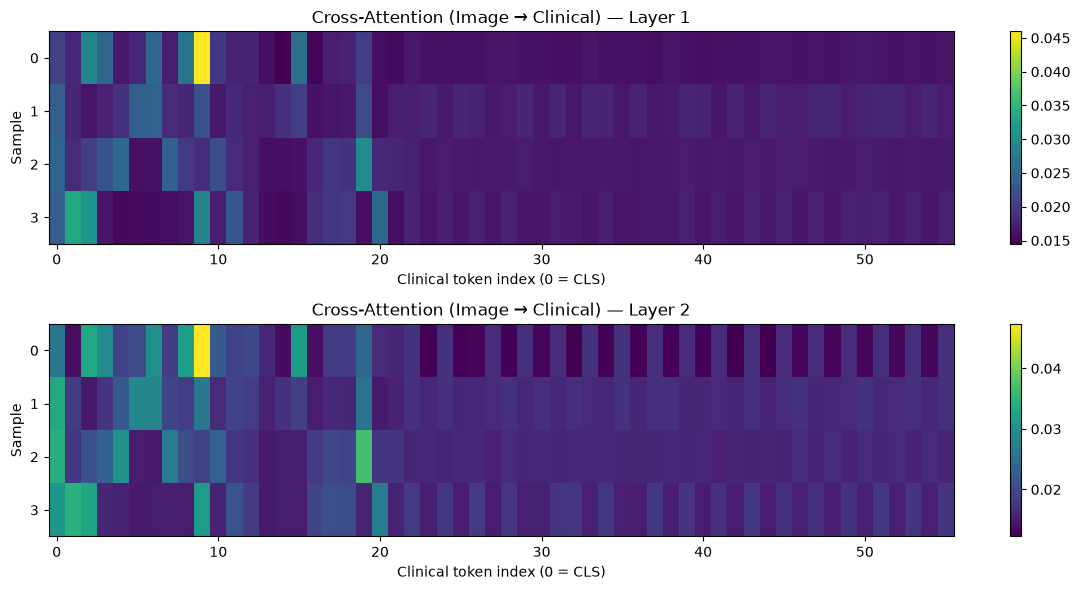


✅ Attention maps saved.


In [18]:
# ==================== CELL 10 : Attention Visualization ====================
image, clinical, y = next(iter(test_loader))
image = image[:4].to(DEVICE)
clinical = clinical[:4].to(DEVICE)

model.eval()
with torch.no_grad():
    logits, attn_maps = model(image, clinical, return_attention=True)

# ---- Inspect shapes first ----
print("Attention map shapes:")
for i, w in enumerate(attn_maps["img_to_clin"]):
    print(f"  Layer {i+1} img_to_clin: {w.shape}")
for i, w in enumerate(attn_maps["clin_to_img"]):
    print(f"  Layer {i+1} clin_to_img: {w.shape}")


n_layers = len(attn_maps["img_to_clin"])
fig, axes = plt.subplots(n_layers, 1, figsize=(12, 3 * n_layers))
if n_layers == 1:
    axes = [axes]

for i, w in enumerate(attn_maps["img_to_clin"]):
    # 🔧 FIX: Handle different weight shapes
    if w.dim() == 4:
        # Shape (B, n_heads, L_q, L_kv) — average heads and queries
        w_mean = w.mean(dim=1).mean(dim=1).numpy()  # (B, L_kv)
    elif w.dim() == 3:
        # Shape (B, L_q, L_kv) — average queries only
        w_mean = w.mean(dim=1).numpy()  # (B, L_kv)
    elif w.dim() == 2:
        # Shape (L_q, L_kv) — no batch dim
        w_mean = w.unsqueeze(0).numpy()  # (1, L_kv)
    else:
        raise ValueError(f"Unexpected attention weight shape: {w.shape}")

    print(f"  Layer {i+1} w_mean shape: {w_mean.shape}")

    im = axes[i].imshow(w_mean, aspect="auto", cmap="viridis")
    axes[i].set_xlabel("Clinical token index (0 = CLS)")
    axes[i].set_ylabel("Sample")
    axes[i].set_title(f"Cross-Attention (Image → Clinical) — Layer {i+1}")
    plt.colorbar(im, ax=axes[i])

plt.tight_layout()
plt.savefig(RESULT_DIR / "attention_maps.png", dpi=200)
plt.show()
print("\n✅ Attention maps saved.")


FINAL MODEL COMPARISON (sorted by Test AUC)
                          model  test_accuracy  test_auc  test_f1  test_recall
           Late-Fusion Baseline         0.7763    0.8510   0.8468       0.7833
Loss-Focal Loss (α=0.25, γ=2.0)         0.7763    0.8510   0.8468       0.7833
                Ablation-Fusion         0.7763    0.8510   0.8468       0.7833
         Ablation-Clinical-Only         0.6053    0.8271   0.6739       0.5167
  Loss-Cross-Entropy (Weighted)         0.6316    0.8156   0.7021       0.5500
                CLIP Fine-Tuned         0.8026    0.7844   0.8889       1.0000
  Cross-Attention Fusion (Ours)         0.6053    0.7354   0.6939       0.5667
            Ablation-Image-Only         0.6842    0.6969   0.7931       0.7667
                 CLIP Zero-Shot         0.7895    0.6260   0.8824       1.0000


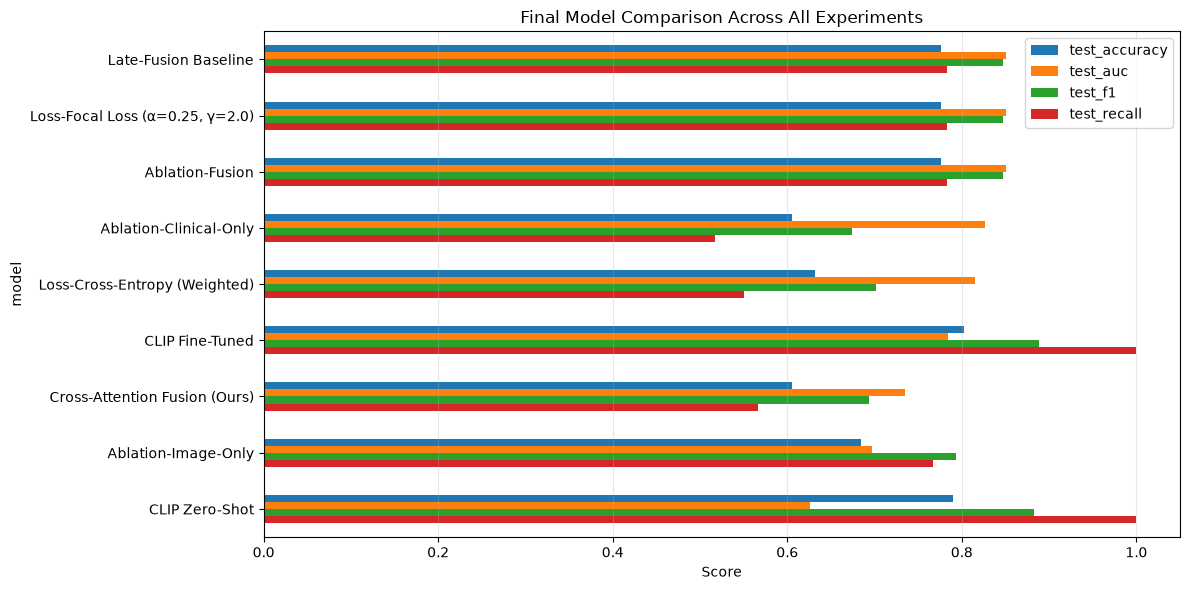


✅ All results saved to: g:\Research Paper\AngioCAD_Project\results


In [20]:
# ==================== CELL 11: Final Comparison Table ====================
final_results = {
    "model": "Cross-Attention Fusion",
    "test_accuracy": test_metrics["accuracy"],
    "test_auc": test_metrics["auc"],
    "test_f1": test_metrics["f1"],
    "test_precision": test_metrics["precision"],
    "test_recall": test_metrics["recall"],
    "best_val_auc": float(checkpoint["best_auc"]),
    "best_epoch": int(checkpoint["epoch"]),
}
with open(RESULT_DIR / "attention_fusion_results.json", "w") as f:
    json.dump(final_results, f, indent=2)

# Build a comparison across all experiments we ran
comparison_rows = [{
    "model": "Cross-Attention Fusion (Ours)",
    "test_accuracy": test_metrics["accuracy"],
    "test_auc": test_metrics["auc"],
    "test_f1": test_metrics["f1"],
    "test_recall": test_metrics["recall"],
}]

# Baseline late-fusion
baseline_json = RESULT_DIR / "test_results.json"
if baseline_json.exists():
    with open(baseline_json) as f:
        base = json.load(f)
    comparison_rows.append({
        "model": "Late-Fusion Baseline",
        "test_accuracy": base["metrics"]["accuracy"],
        "test_auc": base["metrics"]["auc"],
        "test_f1": base["metrics"]["f1"],
        "test_recall": base.get("sensitivity", np.nan),
    })

# Ablations
ablation_csv = RESULT_DIR / "ablation_results.csv"
if ablation_csv.exists():
    abl = pd.read_csv(ablation_csv)
    for _, row in abl.iterrows():
        comparison_rows.append({
            "model": f"Ablation-{row['Model']}",
            "test_accuracy": row["accuracy"],
            "test_auc": row["auc"],
            "test_f1": row["f1"],
            "test_recall": row.get("recall", np.nan),
        })

# Loss comparison
loss_csv = RESULT_DIR / "loss_comparison.csv"
if loss_csv.exists():
    los = pd.read_csv(loss_csv)
    for _, row in los.iterrows():
        comparison_rows.append({
            "model": f"Loss-{row['Loss']}",
            "test_accuracy": row["accuracy"],
            "test_auc": row["auc"],
            "test_f1": row["f1"],
            "test_recall": row["recall"],
        })

# VLM baselines
vlm_csv = RESULT_DIR / "vlm_results.csv"
if vlm_csv.exists():
    vlm = pd.read_csv(vlm_csv)
    for _, row in vlm.iterrows():
        comparison_rows.append({
            "model": row["Model"],
            "test_accuracy": row["accuracy"],
            "test_auc": row["auc"],
            "test_f1": row["f1"],
            "test_recall": row["recall"],
        })

comparison_df = (pd.DataFrame(comparison_rows)
                   .drop_duplicates(subset=["model"])
                   .sort_values("test_auc", ascending=False)
                   .reset_index(drop=True))
comparison_df.to_csv(RESULT_DIR / "final_model_comparison.csv", index=False)

print("\n" + "=" * 78)
print("FINAL MODEL COMPARISON (sorted by Test AUC)")
print("=" * 78)
print(comparison_df.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 6))
comparison_df.set_index("model")[["test_accuracy", "test_auc", "test_f1", "test_recall"]] \
    .plot(kind="barh", ax=ax)
ax.set_title("Final Model Comparison Across All Experiments")
ax.set_xlabel("Score")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / "final_comparison.png", dpi=200)
plt.show()

print(f"\n✅ All results saved to: {RESULT_DIR.absolute()}")